<a href="https://colab.research.google.com/github/GH-Rumi/PCVK26_7_HelmiRR/blob/main/Week09_7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [16]:
from google.colab import drive
drive.mount('/content/drive')

import cv2
import numpy as np
from matplotlib import pyplot as plt

path = '/content/drive/MyDrive/PCVK 2026/Images'

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


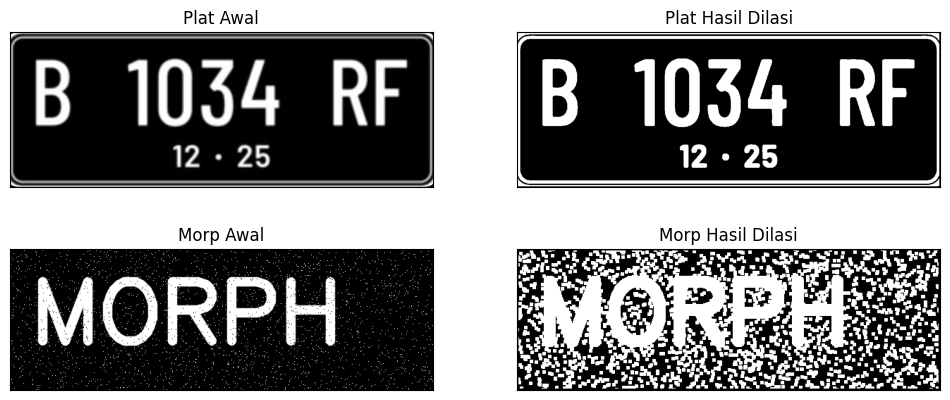

In [17]:
def dilasi_citra(F, w):
    p, q = F.shape
    imgD = np.zeros((p, q), dtype=np.uint8)
    SED = np.ones((w, w), dtype=np.uint8)
    constant1 = (w - 1) // 2

    for i in range(constant1, p - constant1):
        for j in range(constant1, q - constant1):
            temp = F[i-constant1:i+constant1+1, j-constant1:j+constant1+1]
            product = temp * SED
            imgD[i, j] = np.max(product)

    return imgD

img_plat = cv2.imread(path + '/plat_nomer.png', 0)
_, thresh_plat = cv2.threshold(img_plat, 125, 200, cv2.THRESH_BINARY)
imgPlat = dilasi_citra(thresh_plat, 5)

img_morp = cv2.imread(path + '/noisy_text.png', 0)
_, thresh_morp = cv2.threshold(img_morp, 125, 200, cv2.THRESH_BINARY)
imgMorp = dilasi_citra(thresh_morp, 5)

plt.figure(figsize=(12, 5))

plt.subplot(221), plt.imshow(img_plat, cmap='gray')
plt.title('Plat Awal'), plt.xticks([]), plt.yticks([])

plt.subplot(222), plt.imshow(imgPlat, cmap='gray')
plt.title('Plat Hasil Dilasi'), plt.xticks([]), plt.yticks([])

plt.subplot(223), plt.imshow(img_morp, cmap='gray')
plt.title('Morp Awal'), plt.xticks([]), plt.yticks([])

plt.subplot(224), plt.imshow(imgMorp, cmap='gray')
plt.title('Morp Hasil Dilasi'), plt.xticks([]), plt.yticks([])

plt.show()

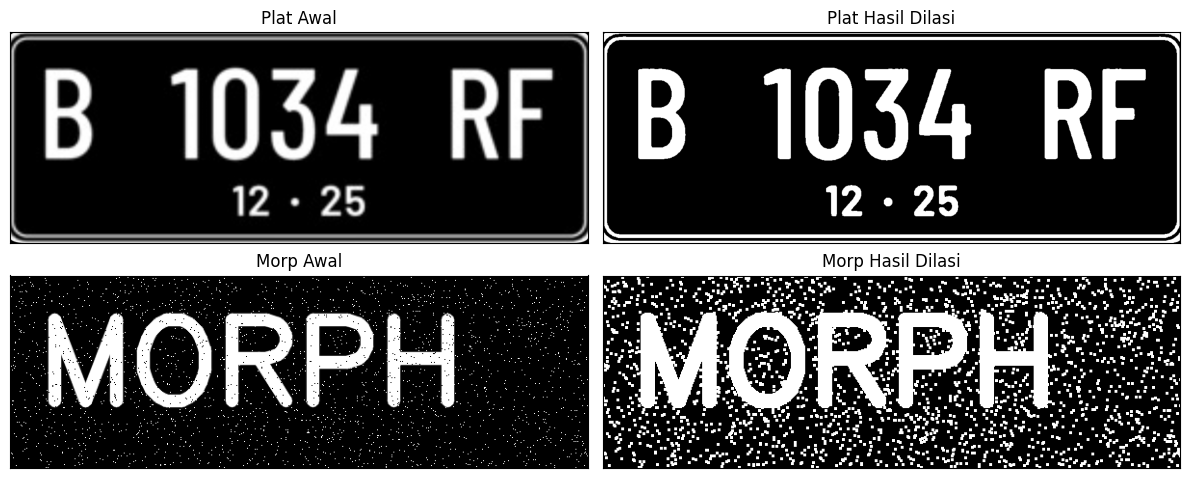

In [18]:
img_plat = cv2.imread(path + '/plat_nomer.png', 0)
_, thresh_plat = cv2.threshold(img_plat, 127, 225, cv2.THRESH_BINARY)
img_morp = cv2.imread(path + '/noisy_text.png', 0)
_, thresh_morp = cv2.threshold(img_morp, 127, 225, cv2.THRESH_BINARY)

kernel = np.ones((3,3), np.uint8)
dilasi_plat = cv2.dilate(thresh_plat, kernel, iterations=1)
dilasi_morp = cv2.dilate(thresh_morp, kernel, iterations=1)

plt.figure(figsize=(12, 5))
plt.subplot(221), plt.imshow(img_plat, cmap='gray'), plt.title('Plat Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(222), plt.imshow(dilasi_plat, cmap='gray'), plt.title('Plat Hasil Dilasi'), plt.xticks([]), plt.yticks([])
plt.subplot(223), plt.imshow(img_morp, cmap='gray'), plt.title('Morp Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(224), plt.imshow(dilasi_morp, cmap='gray'), plt.title('Morp Hasil Dilasi'), plt.xticks([]), plt.yticks([])
plt.tight_layout()
plt.show()

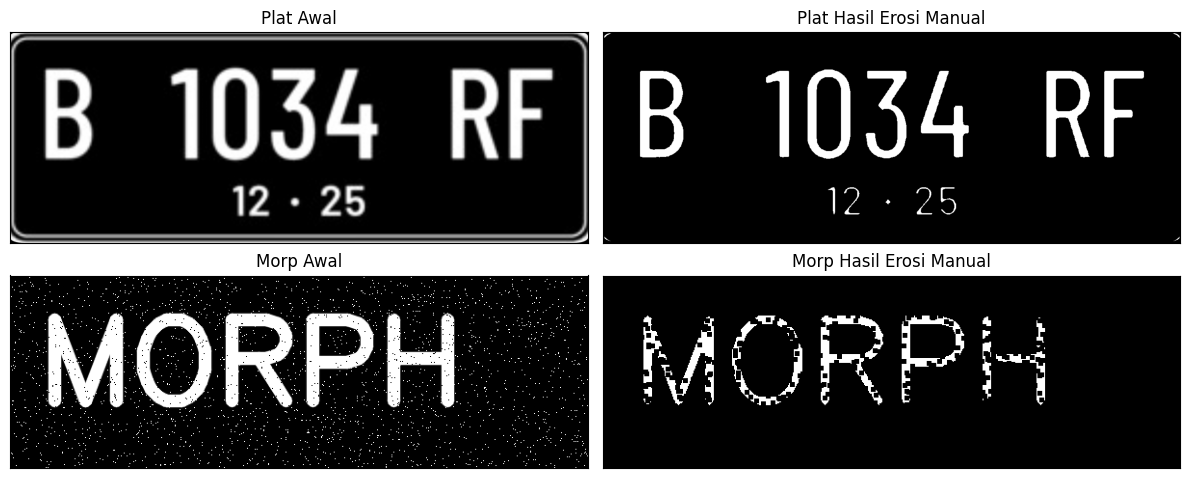

In [19]:
def erosi_citra(F, k):
    m, n = F.shape
    SE = np.ones((k, k), dtype=np.uint8)
    constant = (k - 1) // 2
    imgE = np.zeros((m, n), dtype=np.uint8)
    for i in range(constant, m - constant):
        for j in range(constant, n - constant):
            temp = F[i-constant:i+constant+1, j-constant:j+constant+1]
            product = temp * SE
            imgE[i, j] = np.min(product)
    return imgE

img_plat = cv2.imread(path + '/plat_nomer.png', 0)
_, thresh_plat = cv2.threshold(img_plat, 175, 225, cv2.THRESH_BINARY)
img_morp = cv2.imread(path + '/noisy_text.png', 0)
_, thresh_morp = cv2.threshold(img_morp, 175, 225, cv2.THRESH_BINARY)

k = 5
erosi_plat = erosi_citra(thresh_plat, k)
erosi_morp = erosi_citra(thresh_morp, k)

plt.figure(figsize=(12, 5))
plt.subplot(221), plt.imshow(img_plat, cmap='gray'), plt.title('Plat Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(222), plt.imshow(erosi_plat, cmap='gray'), plt.title('Plat Hasil Erosi Manual'), plt.xticks([]), plt.yticks([])
plt.subplot(223), plt.imshow(img_morp, cmap='gray'), plt.title('Morp Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(224), plt.imshow(erosi_morp, cmap='gray'), plt.title('Morp Hasil Erosi Manual'), plt.xticks([]), plt.yticks([])
plt.tight_layout()
plt.show()

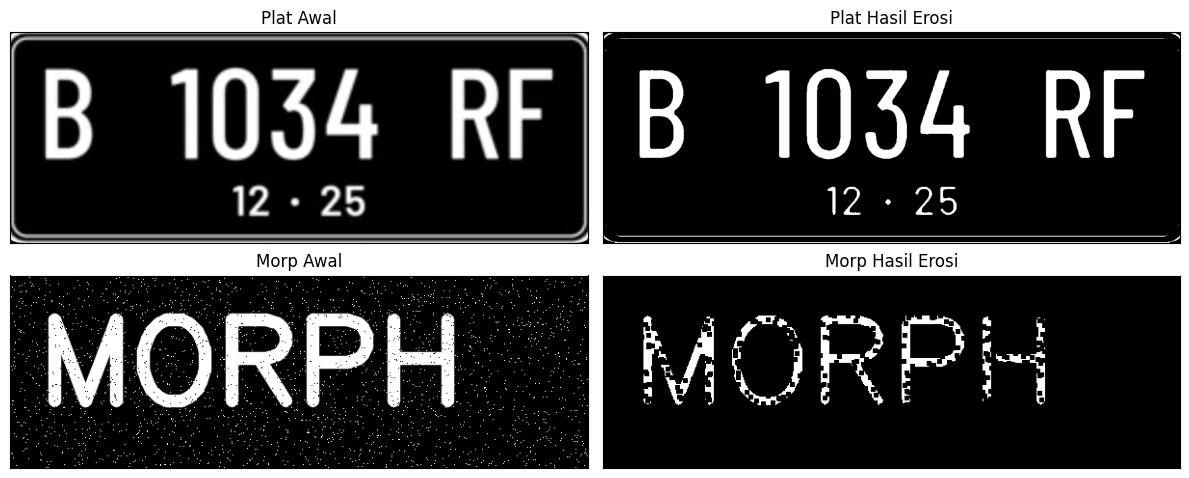

In [20]:
img_plat = cv2.imread(path + '/plat_nomer.png', 0)
_, thresh_plat = cv2.threshold(img_plat, 127, 225, cv2.THRESH_BINARY)
img_morp = cv2.imread(path + '/noisy_text.png', 0)
_, thresh_morp = cv2.threshold(img_morp, 127, 225, cv2.THRESH_BINARY)

kernel = np.ones((5,5), np.uint8)
erosion_plat = cv2.erode(thresh_plat, kernel, iterations=1)
erosion_morp = cv2.erode(thresh_morp, kernel, iterations=1)

plt.figure(figsize=(12, 5))
plt.subplot(221), plt.imshow(img_plat, cmap='gray'), plt.title('Plat Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(222), plt.imshow(erosion_plat, cmap='gray'), plt.title('Plat Hasil Erosi'), plt.xticks([]), plt.yticks([])
plt.subplot(223), plt.imshow(img_morp, cmap='gray'), plt.title('Morp Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(224), plt.imshow(erosion_morp, cmap='gray'), plt.title('Morp Hasil Erosi'), plt.xticks([]), plt.yticks([])
plt.tight_layout()
plt.show()

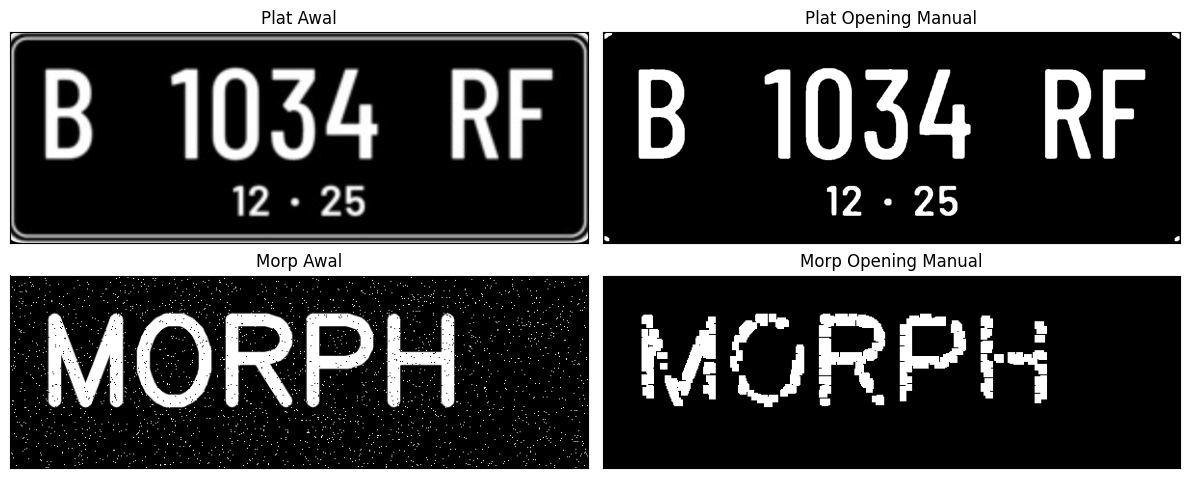

In [33]:
img_plat = cv2.imread(path + '/plat_nomer.png', 0)
_, thresh_plat = cv2.threshold(img_plat, 127, 225, cv2.THRESH_BINARY)
img_morp = cv2.imread(path + '/noisy_text.png', 0)
_, thresh_morp = cv2.threshold(img_morp, 127, 225, cv2.THRESH_BINARY)

k = 7

open_plat_manual = dilasi_citra(erosi_citra(thresh_plat, k), k)
open_morp_manual = dilasi_citra(erosi_citra(thresh_morp, k), k)

plt.figure(figsize=(12, 5))
plt.subplot(221), plt.imshow(img_plat, cmap='gray'), plt.title('Plat Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(222), plt.imshow(open_plat_manual, cmap='gray'), plt.title('Plat Opening Manual'), plt.xticks([]), plt.yticks([])
plt.subplot(223), plt.imshow(img_morp, cmap='gray'), plt.title('Morp Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(224), plt.imshow(open_morp_manual, cmap='gray'), plt.title('Morp Opening Manual'), plt.xticks([]), plt.yticks([])
plt.tight_layout()
plt.show()

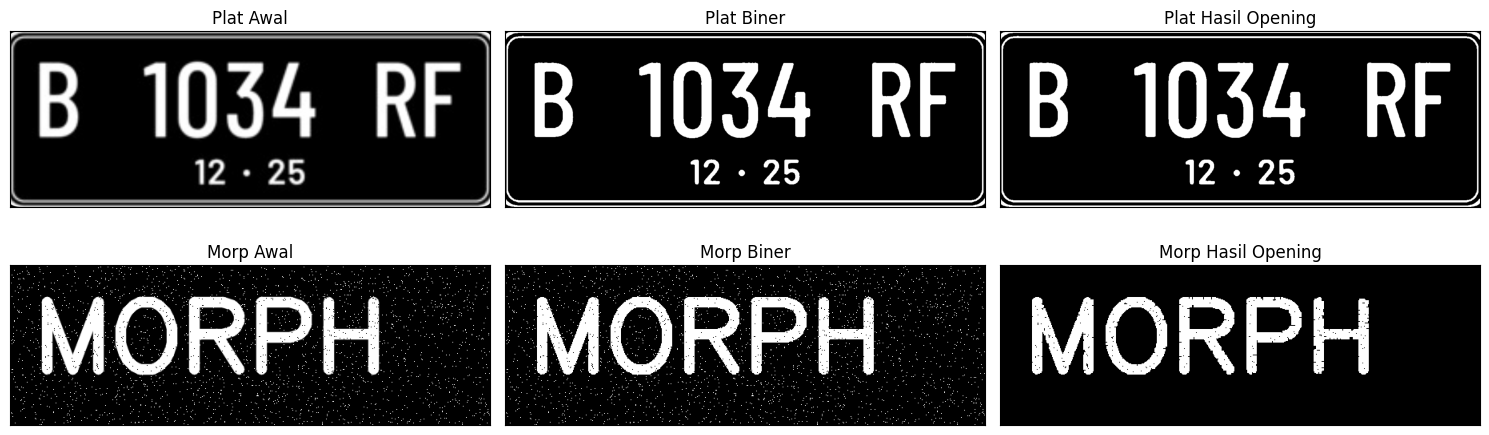

In [36]:
img_plat = cv2.imread(path + '/plat_nomer.png', 0)
_, thresh_plat = cv2.threshold(img_plat, 127, 225, cv2.THRESH_BINARY)
img_morp = cv2.imread(path + '/noisy_text.png', 0)
_, thresh_morp = cv2.threshold(img_morp, 127, 225, cv2.THRESH_BINARY)

kernel = np.ones((3,3), np.uint8)
open_plat = cv2.morphologyEx(thresh_plat, cv2.MORPH_OPEN, kernel)
open_morp = cv2.morphologyEx(thresh_morp, cv2.MORPH_OPEN, kernel)

plt.figure(figsize=(15, 5))

plt.subplot(231), plt.imshow(img_plat, cmap='gray'), plt.title('Plat Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(232), plt.imshow(thresh_plat, cmap='gray'), plt.title('Plat Biner'), plt.xticks([]), plt.yticks([])
plt.subplot(233), plt.imshow(open_plat, cmap='gray'), plt.title('Plat Hasil Opening'), plt.xticks([]), plt.yticks([])

plt.subplot(234), plt.imshow(img_morp, cmap='gray'), plt.title('Morp Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(235), plt.imshow(thresh_morp, cmap='gray'), plt.title('Morp Biner'), plt.xticks([]), plt.yticks([])
plt.subplot(236), plt.imshow(open_morp, cmap='gray'), plt.title('Morp Hasil Opening'), plt.xticks([]), plt.yticks([])

plt.tight_layout()
plt.show()

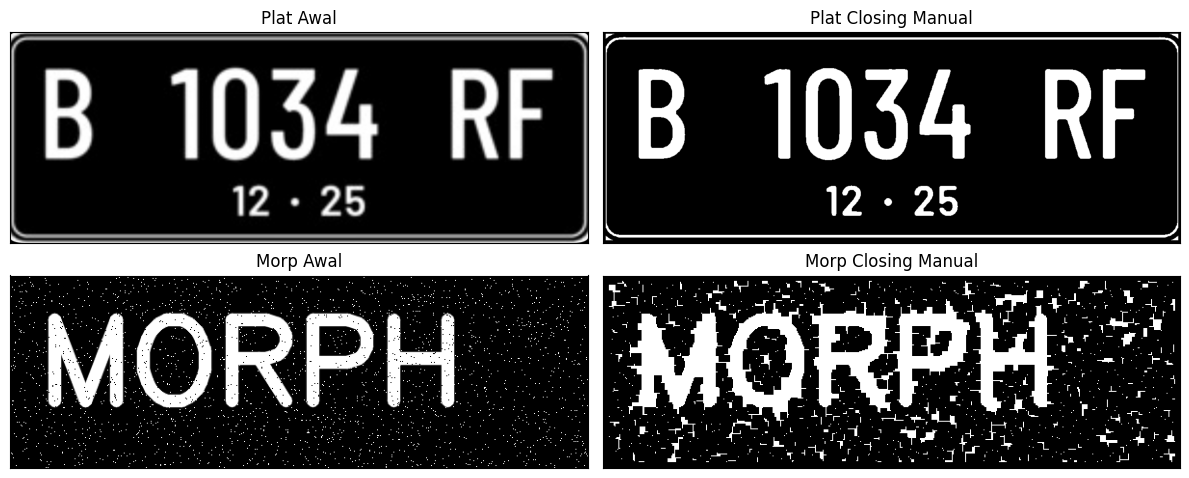

In [35]:
img_plat = cv2.imread(path + '/plat_nomer.png', 0)
_, thresh_plat = cv2.threshold(img_plat, 127, 225, cv2.THRESH_BINARY)
img_morp = cv2.imread(path + '/noisy_text.png', 0)
_, thresh_morp = cv2.threshold(img_morp, 127, 225, cv2.THRESH_BINARY)

k = 7

close_plat_manual = erosi_citra(dilasi_citra(thresh_plat, k), k)
close_morp_manual = erosi_citra(dilasi_citra(thresh_morp, k), k)

plt.figure(figsize=(12, 5))
plt.subplot(221), plt.imshow(img_plat, cmap='gray'), plt.title('Plat Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(222), plt.imshow(close_plat_manual, cmap='gray'), plt.title('Plat Closing Manual'), plt.xticks([]), plt.yticks([])
plt.subplot(223), plt.imshow(img_morp, cmap='gray'), plt.title('Morp Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(224), plt.imshow(close_morp_manual, cmap='gray'), plt.title('Morp Closing Manual'), plt.xticks([]), plt.yticks([])
plt.tight_layout()
plt.show()

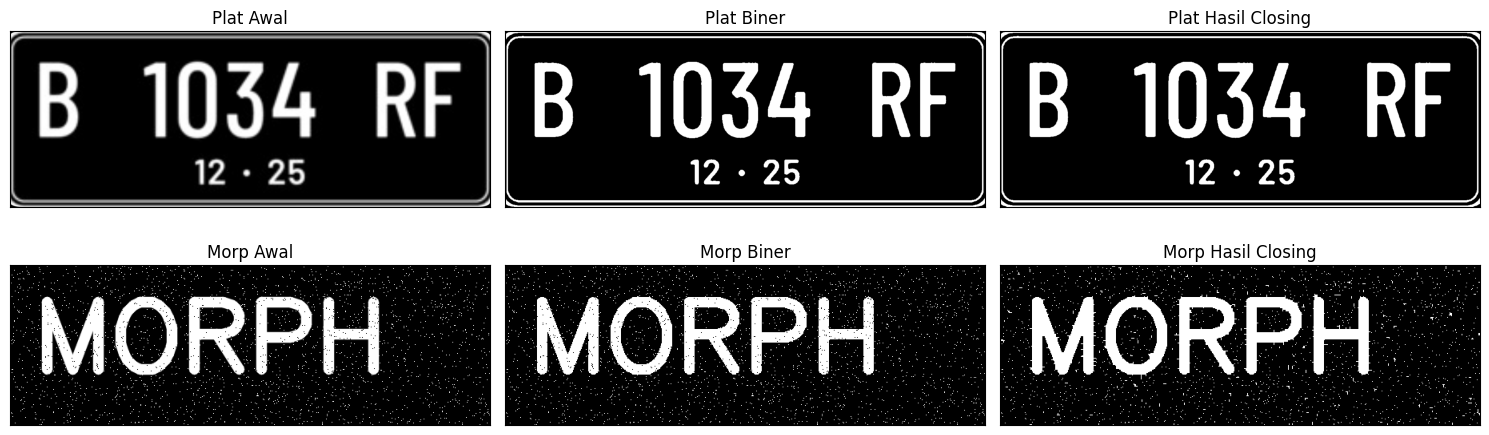

In [37]:
img_plat = cv2.imread(path + '/plat_nomer.png', 0)
_, thresh_plat = cv2.threshold(img_plat, 127, 225, cv2.THRESH_BINARY)
img_morp = cv2.imread(path + '/noisy_text.png', 0)
_, thresh_morp = cv2.threshold(img_morp, 127, 225, cv2.THRESH_BINARY)

kernel = np.ones((3,3), np.uint8)
close_plat = cv2.morphologyEx(thresh_plat, cv2.MORPH_CLOSE, kernel)
close_morp = cv2.morphologyEx(thresh_morp, cv2.MORPH_CLOSE, kernel)

plt.figure(figsize=(15, 5))

plt.subplot(231), plt.imshow(img_plat, cmap='gray'), plt.title('Plat Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(232), plt.imshow(thresh_plat, cmap='gray'), plt.title('Plat Biner'), plt.xticks([]), plt.yticks([])
plt.subplot(233), plt.imshow(close_plat, cmap='gray'), plt.title('Plat Hasil Closing'), plt.xticks([]), plt.yticks([])

plt.subplot(234), plt.imshow(img_morp, cmap='gray'), plt.title('Morp Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(235), plt.imshow(thresh_morp, cmap='gray'), plt.title('Morp Biner'), plt.xticks([]), plt.yticks([])
plt.subplot(236), plt.imshow(close_morp, cmap='gray'), plt.title('Morp Hasil Closing'), plt.xticks([]), plt.yticks([])

plt.tight_layout()
plt.show()

SED = CROSS 3x3


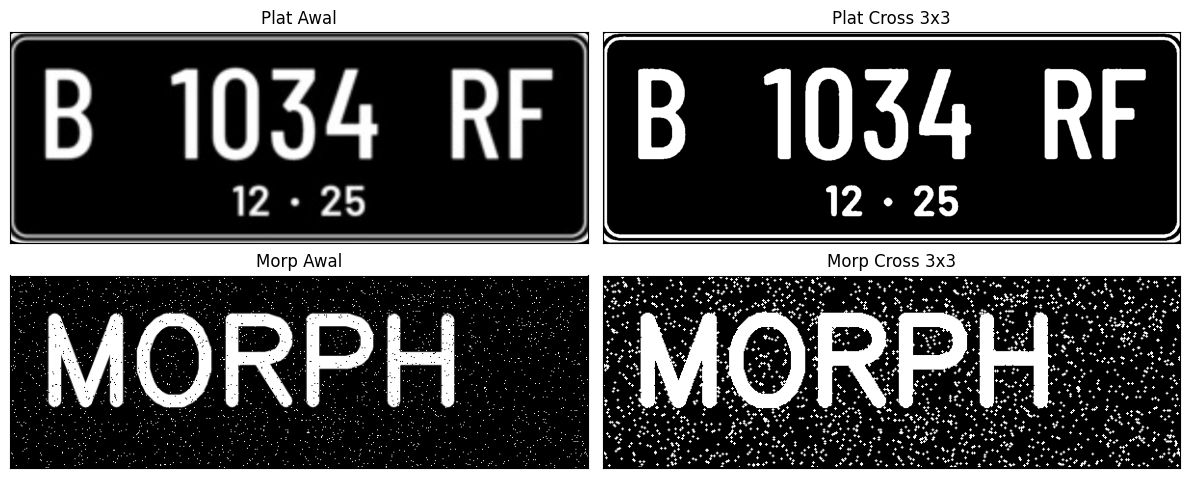

In [23]:
def dilasi_citra_cross(F, w, is_5x5=False):
    p, q = F.shape
    imgD = np.zeros((p, q), dtype=np.uint8)
    if is_5x5:
        SED = np.array([[0,0,1,0,0],
                        [0,0,1,0,0],
                        [1,1,1,1,1],
                        [0,0,1,0,0],
                        [0,0,1,0,0]], dtype=np.uint8)
    else:
        SED = np.array([[0,1,0],
                        [1,1,1],
                        [0,1,0]], dtype=np.uint8)

    constant1 = (w - 1) // 2
    for i in range(constant1, p - constant1):
        for j in range(constant1, q - constant1):
            temp = F[i-constant1:i+constant1+1, j-constant1:j+constant1+1]
            product = temp * SED
            imgD[i, j] = np.max(product)
    return imgD

img_plat = cv2.imread(path + '/plat_nomer.png', 0)
_, thresh_plat = cv2.threshold(img_plat, 127, 225, cv2.THRESH_BINARY)
img_morp = cv2.imread(path + '/noisy_text.png', 0)
_, thresh_morp = cv2.threshold(img_morp, 127, 225, cv2.THRESH_BINARY)

res_plat = dilasi_citra_cross(thresh_plat, 3, False)
res_morp = dilasi_citra_cross(thresh_morp, 3, False)

print("SED = CROSS 3x3")
plt.figure(figsize=(12, 5))
plt.subplot(221), plt.imshow(img_plat, cmap='gray'), plt.title('Plat Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(222), plt.imshow(res_plat, cmap='gray'), plt.title('Plat Cross 3x3'), plt.xticks([]), plt.yticks([])
plt.subplot(223), plt.imshow(img_morp, cmap='gray'), plt.title('Morp Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(224), plt.imshow(res_morp, cmap='gray'), plt.title('Morp Cross 3x3'), plt.xticks([]), plt.yticks([])
plt.tight_layout()
plt.show()

SED = CIRCULAR 5x5


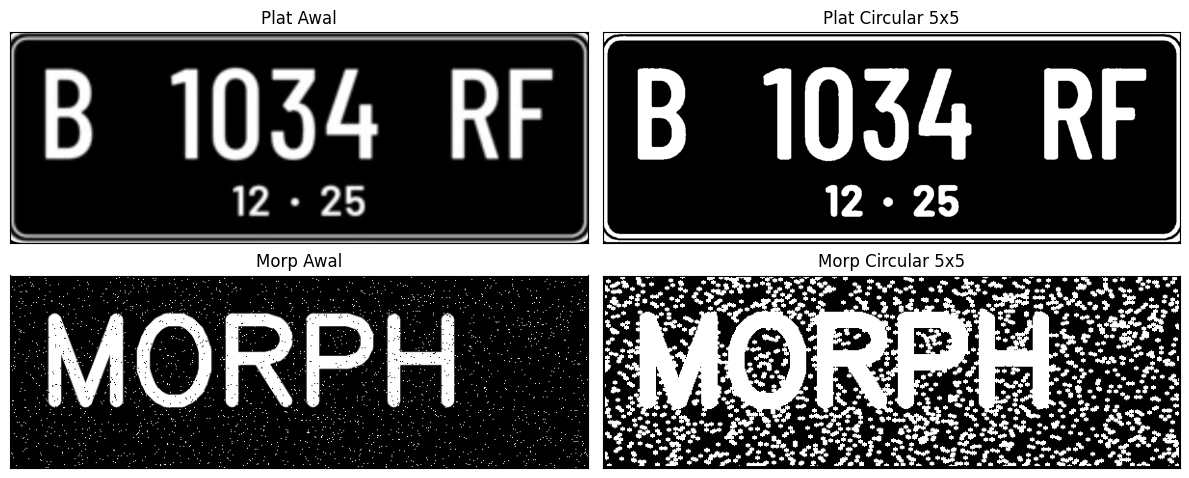

In [24]:
def dilasi_citra_circular(F, w):
    p, q = F.shape
    imgD = np.zeros((p, q), dtype=np.uint8)
    SED = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (w, w))
    constant1 = (w - 1) // 2
    for i in range(constant1, p - constant1):
        for j in range(constant1, q - constant1):
            temp = F[i-constant1:i+constant1+1, j-constant1:j+constant1+1]
            product = temp * SED
            imgD[i, j] = np.max(product)
    return imgD

img_plat = cv2.imread(path + '/plat_nomer.png', 0)
_, thresh_plat = cv2.threshold(img_plat, 127, 225, cv2.THRESH_BINARY)
img_morp = cv2.imread(path + '/noisy_text.png', 0)
_, thresh_morp = cv2.threshold(img_morp, 127, 225, cv2.THRESH_BINARY)

res_plat = dilasi_citra_circular(thresh_plat, 5)
res_morp = dilasi_citra_circular(thresh_morp, 5)

print("SED = CIRCULAR 5x5")
plt.figure(figsize=(12, 5))
plt.subplot(221), plt.imshow(img_plat, cmap='gray'), plt.title('Plat Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(222), plt.imshow(res_plat, cmap='gray'), plt.title('Plat Circular 5x5'), plt.xticks([]), plt.yticks([])
plt.subplot(223), plt.imshow(img_morp, cmap='gray'), plt.title('Morp Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(224), plt.imshow(res_morp, cmap='gray'), plt.title('Morp Circular 5x5'), plt.xticks([]), plt.yticks([])
plt.tight_layout()
plt.show()

SE = RECTANGLE 3x5


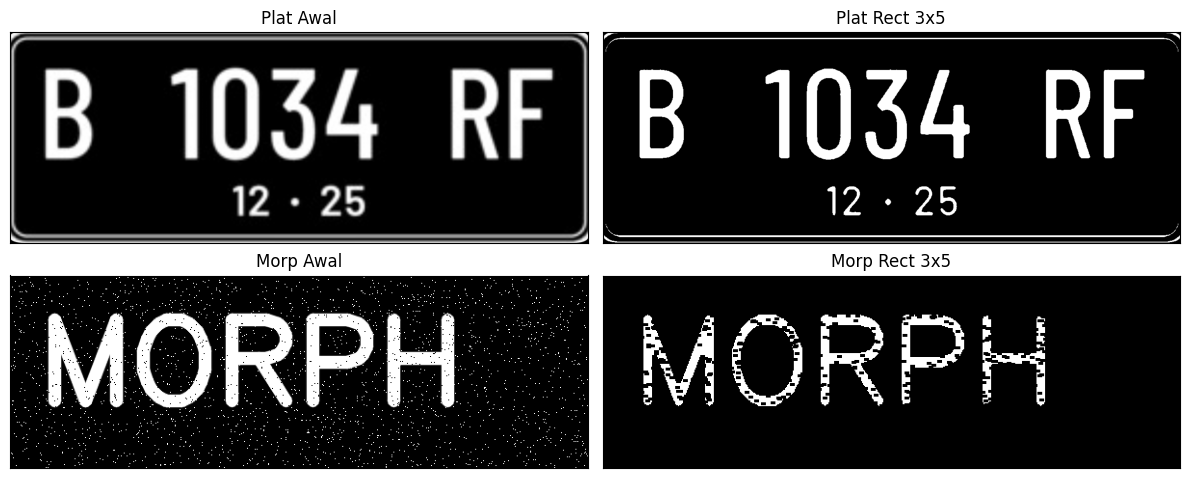

In [25]:
def erosi_citra_rect(F, p, l):
    m, n = F.shape
    SE = cv2.getStructuringElement(cv2.MORPH_RECT, (p, l))
    constant1 = (l - 1) // 2
    constant2 = (p - 1) // 2
    imgE = np.zeros((m, n), dtype=np.uint8)
    for i in range(constant1, m - constant1):
        for j in range(constant2, n - constant2):
            temp = F[i-constant1:i+constant1+1, j-constant2:j+constant2+1]
            product = temp * SE
            imgE[i, j] = np.min(product)
    return imgE

img_plat = cv2.imread(path + '/plat_nomer.png', 0)
_, thresh_plat = cv2.threshold(img_plat, 127, 225, cv2.THRESH_BINARY)
img_morp = cv2.imread(path + '/noisy_text.png', 0)
_, thresh_morp = cv2.threshold(img_morp, 127, 225, cv2.THRESH_BINARY)

res_plat = erosi_citra_rect(thresh_plat, 5, 3) # Rectangle 3x5
res_morp = erosi_citra_rect(thresh_morp, 5, 3)

print("SE = RECTANGLE 3x5")
plt.figure(figsize=(12, 5))
plt.subplot(221), plt.imshow(img_plat, cmap='gray'), plt.title('Plat Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(222), plt.imshow(res_plat, cmap='gray'), plt.title('Plat Rect 3x5'), plt.xticks([]), plt.yticks([])
plt.subplot(223), plt.imshow(img_morp, cmap='gray'), plt.title('Morp Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(224), plt.imshow(res_morp, cmap='gray'), plt.title('Morp Rect 3x5'), plt.xticks([]), plt.yticks([])
plt.tight_layout()
plt.show()

SE = LINE VERTIKAL 5


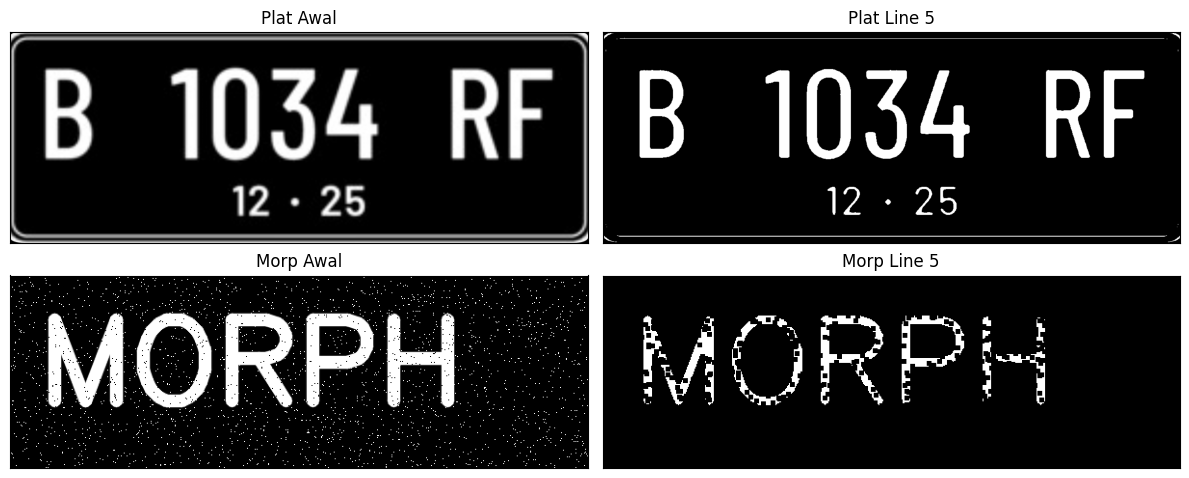

In [26]:
def erosi_citra_line(F, k):
    m, n = F.shape
    SE = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (1, k))
    constant = (k - 1) // 2
    imgE = np.zeros((m, n), dtype=np.uint8)
    for i in range(constant, m - constant):
        for j in range(constant, n - constant):
            temp = F[i-constant:i+constant+1, j-constant:j+constant+1]
            product = temp * SE
            imgE[i, j] = np.min(product)
    return imgE

img_plat = cv2.imread(path + '/plat_nomer.png', 0)
_, thresh_plat = cv2.threshold(img_plat, 127, 225, cv2.THRESH_BINARY)
img_morp = cv2.imread(path + '/noisy_text.png', 0)
_, thresh_morp = cv2.threshold(img_morp, 127, 225, cv2.THRESH_BINARY)

res_plat = erosi_citra_line(thresh_plat, 5) # Line Vertikal 5
res_morp = erosi_citra_line(thresh_morp, 5)

print("SE = LINE VERTIKAL 5")
plt.figure(figsize=(12, 5))
plt.subplot(221), plt.imshow(img_plat, cmap='gray'), plt.title('Plat Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(222), plt.imshow(res_plat, cmap='gray'), plt.title('Plat Line 5'), plt.xticks([]), plt.yticks([])
plt.subplot(223), plt.imshow(img_morp, cmap='gray'), plt.title('Morp Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(224), plt.imshow(res_morp, cmap='gray'), plt.title('Morp Line 5'), plt.xticks([]), plt.yticks([])
plt.tight_layout()
plt.show()

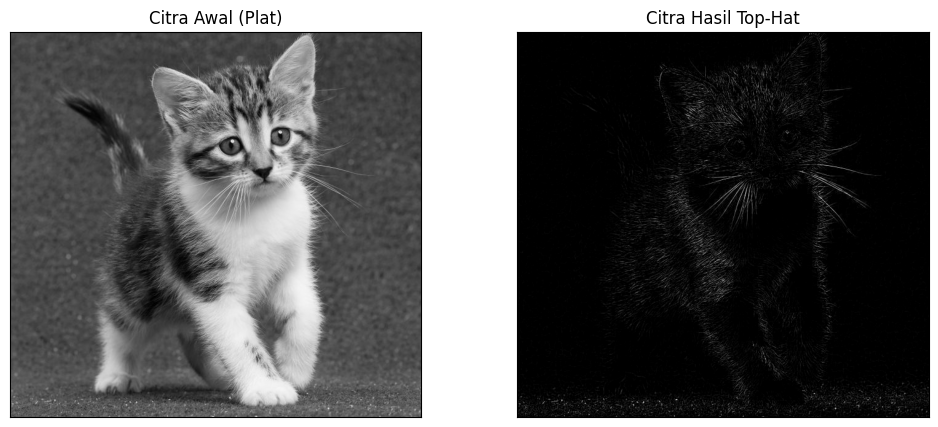

In [27]:
filterSize = (3, 3)
kernel = cv2.getStructuringElement(cv2.MORPH_RECT, filterSize)

img_plat = cv2.imread(path + '/kitten01 (1).jpg', 0)
tophat_img = cv2.morphologyEx(img_plat, cv2.MORPH_TOPHAT, kernel)

plt.figure(figsize=(12, 5))
plt.subplot(121), plt.imshow(img_plat, cmap='gray')
plt.title('Citra Awal (Plat)'), plt.xticks([]), plt.yticks([])
plt.subplot(122), plt.imshow(tophat_img, cmap='gray')
plt.title('Citra Hasil Top-Hat'), plt.xticks([]), plt.yticks([])
plt.show()

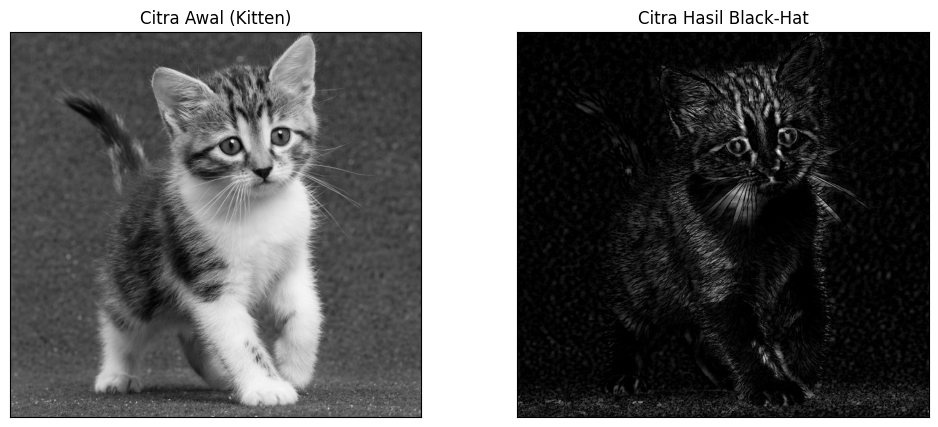

In [29]:
kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (13, 5))

img_kitten = cv2.imread(path + '/kitten01 (1).jpg', 0)
blackhat = cv2.morphologyEx(img_kitten, cv2.MORPH_BLACKHAT, kernel)

plt.figure(figsize=(12, 5))
plt.subplot(121), plt.imshow(img_kitten, cmap='gray')
plt.title('Citra Awal (Kitten)'), plt.xticks([]), plt.yticks([])
plt.subplot(122), plt.imshow(blackhat, cmap='gray')
plt.title('Citra Hasil Black-Hat'), plt.xticks([]), plt.yticks([])
plt.show()

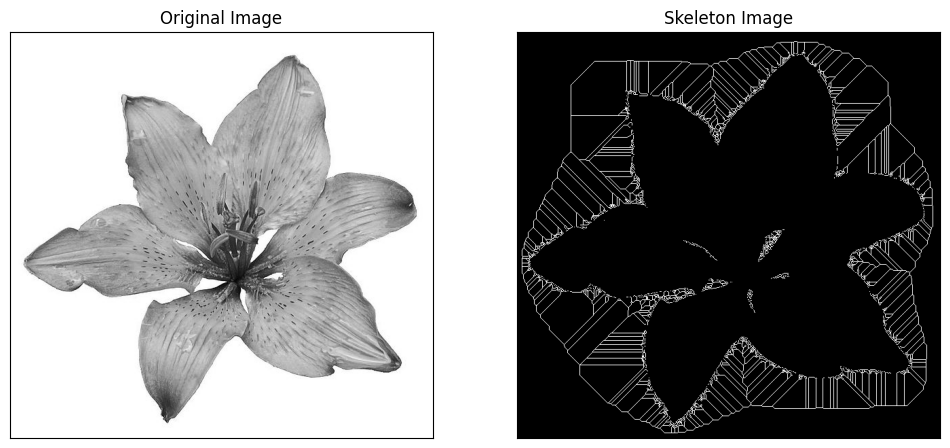

In [30]:
import cv2 as cv
from skimage import filters
from skimage.morphology import skeletonize

img_lily = cv.imread(path + '/lily.jpg', 0)
binary = img_lily > filters.threshold_triangle(img_lily)

binary_cp = binary.copy()
binary_cp[binary_cp == True] = 1
binary_cp[binary_cp == False] = 0

skeleton = skeletonize(binary_cp)

plt.figure(figsize=(12, 6))
plt.subplot(121), plt.imshow(img_lily, cmap='gray')
plt.title('Original Image'), plt.xticks([]), plt.yticks([])
plt.subplot(122), plt.imshow(skeleton, cmap='gray')
plt.title('Skeleton Image'), plt.xticks([]), plt.yticks([])
plt.show()

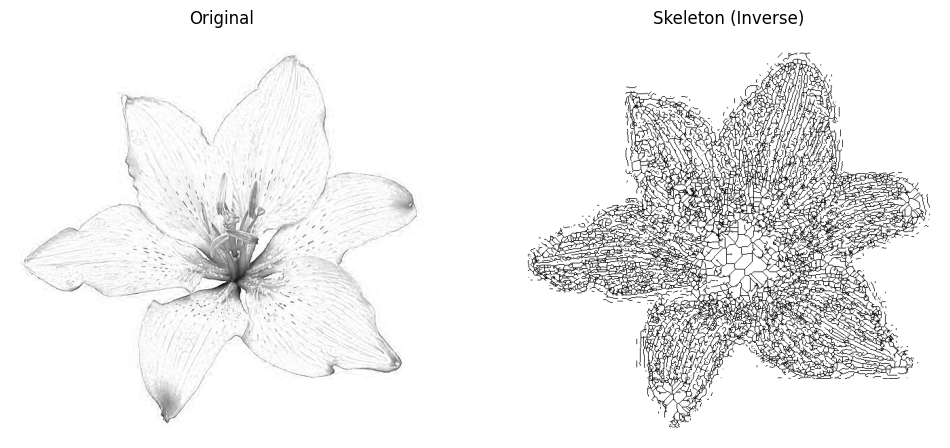

In [31]:
from skimage import io, filters
from skimage.morphology import skeletonize

img_lily = io.imread(path + '/lily.jpg')[..., 0]
binary = img_lily < filters.threshold_triangle(img_lily)
skeleton_inv = skeletonize(binary)

fig, ax = plt.subplots(1, 2, figsize=(12, 6))
ax[0].imshow(img_lily, cmap='gray')
ax[0].set_title('Original')
ax[0].set_axis_off()

ax[1].imshow(skeleton_inv, cmap='gray_r')
ax[1].set_title('Skeleton (Inverse)')
ax[1].set_axis_off()
plt.show()

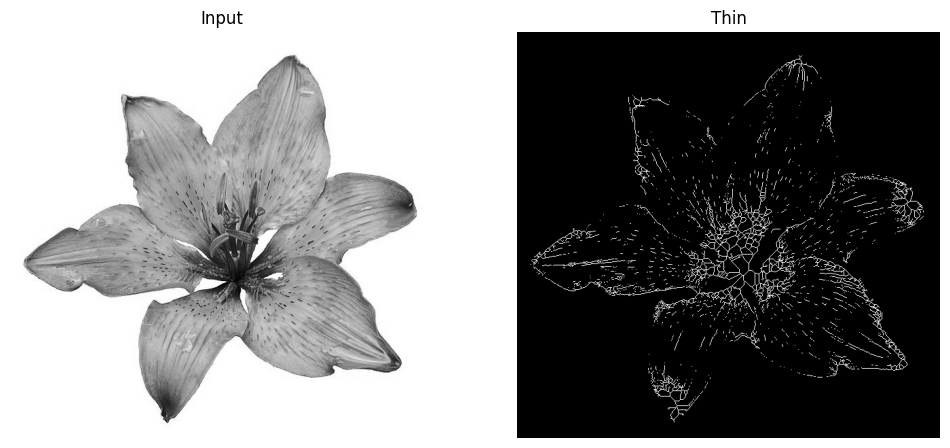

In [32]:
from skimage import img_as_float, io, color, morphology

image = img_as_float(color.rgb2gray(io.imread(path + '/lily.jpg')))
image_binary = image < 0.5
out_thin = morphology.thin(image_binary)

fig, ax = plt.subplots(1, 2, figsize=(12, 6))
ax[0].imshow(image, cmap='gray')
ax[0].set_title('Input')
ax[0].set_axis_off()

ax[1].imshow(out_thin, cmap='gray')
ax[1].set_title('Thin')
ax[1].set_axis_off()
plt.show()